# Week 4 — Best denoising strategy: luma/chroma two-stage filter

**TL;DR**

- **Method**: keep the Week 3 impulse detector. For flagged images, convert to **YCrCb** and treat brightness and colour separately:
  - **Y** (brightness): median 3×3 → **NL-means** (h = 4, 7×7 patches, 11×11 search window)
  - **Cr, Cb** (colour): median 5×5 → **Gaussian 21×21**
- **Result** on the 9 impulse-noise images of QSD1-W4 (vs the clean references):

  | | PSNR (dB) | SSIM |
  |---|---|---|
  | no filter | 23.35 | 0.468 |
  | Week 3 (median 3×3) | 30.25 | 0.847 |
  | **Week 4 (this notebook)** | **31.62** | **0.874** |

  It beats Week 3 on **9/9 images** in both PSNR and SSIM. Cost is ~0.2 s per megapixel, and the other 21 images are left untouched.
- **Why it works**: after JPEG compression the noise has three parts (impulse cores, a grainy halo around them, and colour blotches),
  and each stage targets one of them (§1–§3).

This notebook (1) shows what the noise really looks like, (2) implements the method step by step,
(3) explains *why* each step is there and why it beats the alternatives, and (4) checks it on the whole QSD1-W4 set.

The full comparison of methods is produced by `searches/denoising_search.py`
(results in `searches/results/denoising_search*.csv`).

In [1]:
import pickle
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage.metrics import structural_similarity

W4_DIR = Path.cwd() if (Path.cwd() / "utils.py").exists() else Path.cwd() / "w4"
DATA_DIR = W4_DIR.parent / "data"
NOISY_DIR = DATA_DIR / "qsd1_w4"
CLEAN_DIR = NOISY_DIR / "non_augmented"
SEARCH_DIR = W4_DIR / "searches" / "results"


def read_bgr(path: Path) -> np.ndarray:
    # IGNORE_ORIENTATION: some noisy/clean pairs have different EXIF rotation tags
    img = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if img is None:
        raise FileNotFoundError(path)
    return img


with open(NOISY_DIR / "augmentations.pkl", "rb") as f:
    augmentations = pickle.load(f)

ids = sorted(int(p.stem) for p in NOISY_DIR.glob("*.jpg"))
noisy = {i: read_bgr(NOISY_DIR / f"{i:05d}.jpg") for i in ids}
clean = {i: read_bgr(CLEAN_DIR / f"{i:05d}.jpg") for i in ids}
impulse_ids = [i for i in ids if "ImpulseNoise" in augmentations[i]]
print("Impulse-noise images:", impulse_ids)

Impulse-noise images: [3, 8, 12, 17, 19, 22, 23, 24, 25]


In [2]:
PSNR_CAP = 60.0


def psnr(img, ref):
    mse = np.mean((img.astype(np.float64) - ref.astype(np.float64)) ** 2)
    return PSNR_CAP if mse == 0 else min(PSNR_CAP, 10 * np.log10(255 ** 2 / mse))


def ssim(img, ref):
    return structural_similarity(cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY),
                                 cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), data_range=255)


def crop(img, y, x, size):
    return img[y:y + size, x:x + size]


def show(images, titles, cmap=None, figsize=None, vmin=None, vmax=None):
    fig, axes = plt.subplots(1, len(images), figsize=figsize or (4.2 * len(images), 4.2))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), interpolation="nearest")
        else:
            ax.imshow(img, cmap=cmap or "gray", interpolation="nearest", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. What the noise really is

The augmentation is called *impulse noise*, but what reaches us is **impulse noise that has then been JPEG-compressed**,
and that changes everything:

- The impulses have **random values** (not just 0/255 salt & pepper).
- JPEG works in **YCrCb**: it keeps the brightness channel **Y** at full resolution, but stores the two colour channels
  **Cr/Cb at half resolution** and quantizes all of them in 8×8 DCT blocks.
  - In **Y**, each impulse stays a sharp dot but gets a halo of ringing around it.
  - In **Cr/Cb**, impulses are averaged over 2×2 pixels and blurred into soft coloured **blotches**.
- So although only ~2% of the pixels are impulses, **around half of the pixels end up modified** (table below).

Let's look at it on a zoomed crop.

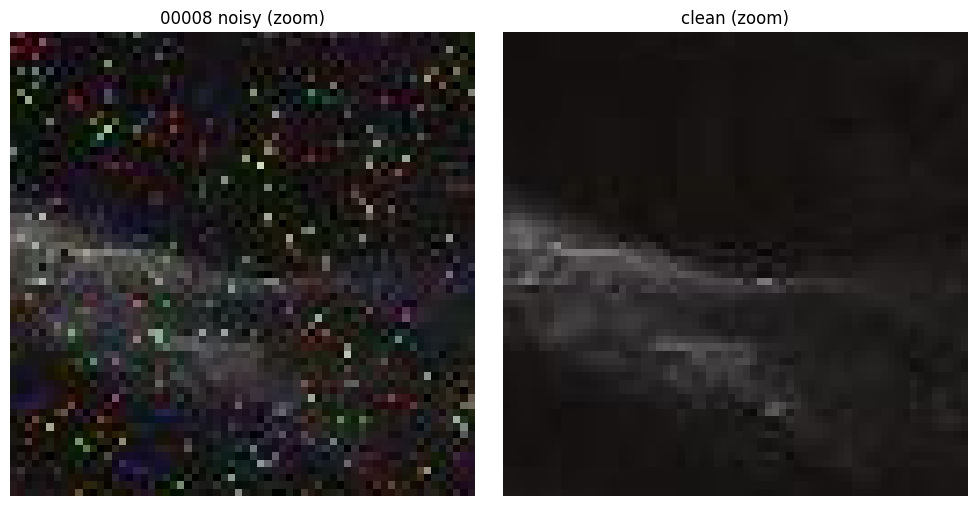

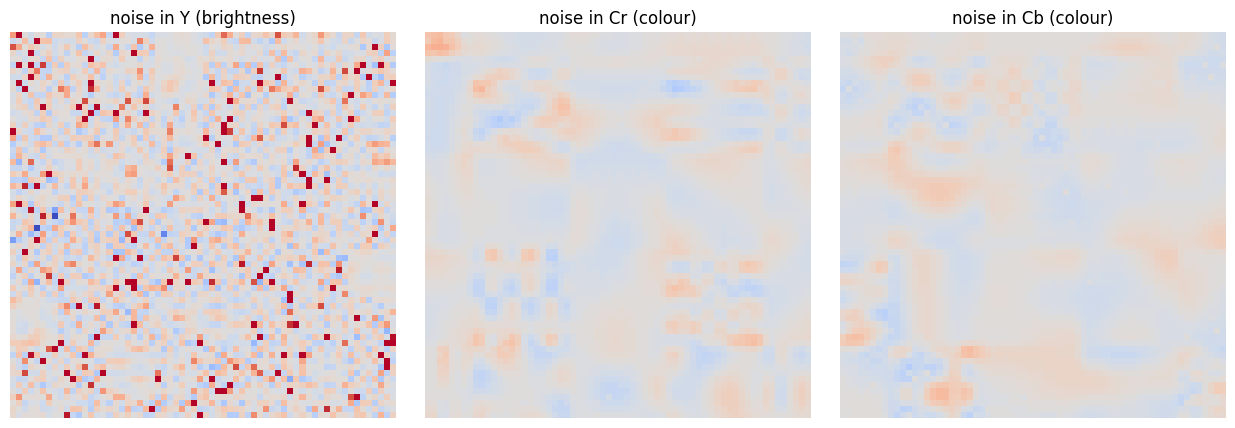

In [3]:
EXAMPLE = 8
CY, CX, CS = 300, 200, 64     # zoom crop (y, x, size)

n, c = noisy[EXAMPLE], clean[EXAMPLE]
show([crop(n, CY, CX, CS), crop(c, CY, CX, CS)],
     [f"{EXAMPLE:05d} noisy (zoom)", "clean (zoom)"], figsize=(10, 5))

ycc_n = cv2.cvtColor(n, cv2.COLOR_BGR2YCrCb).astype(np.int16)
ycc_c = cv2.cvtColor(c, cv2.COLOR_BGR2YCrCb).astype(np.int16)
diff = ycc_n - ycc_c
show([crop(diff[..., k], CY, CX, CS) for k in range(3)],
     ["noise in Y (brightness)", "noise in Cr (colour)", "noise in Cb (colour)"],
     cmap="coolwarm", vmin=-60, vmax=60)

In [4]:
rows = []
for i in impulse_ids:
    d = np.abs(noisy[i].astype(np.int16) - clean[i].astype(np.int16)).max(axis=2)
    rows.append({"id": i, "impulse cores (|diff| > 60)": (d > 60).mean(),
                 "pixels modified (|diff| > 10)": (d > 10).mean()})
display(pd.DataFrame(rows).set_index("id").style.format("{:.1%}"))

,impulse cores (|diff| > 60),pixels modified (|diff| > 10)
id,,
3,2.1%,48.7%
8,2.5%,48.4%
12,1.7%,47.4%
17,1.5%,40.2%
19,2.3%,52.5%
22,2.1%,50.1%
23,1.8%,43.5%
24,1.9%,46.2%
25,2.5%,47.9%


**Consequences for the design of the filter**

| Noise component | Where | What removes it |
|---|---|---|
| Impulse cores (sharp, high-amplitude, random value) | Y | an order-statistic filter: **median** (a mean would just spread them) |
| JPEG halo around each impulse (low amplitude, spread) | Y | an **edge-preserving smoother** that can tell noise from painting texture |
| Colour blotches (low frequency, ~2–16 px) | Cr, Cb | **strong smoothing**; a 3×3 median is far too small for them |

This is why a single filter (Week 3: median 3×3 on BGR) cannot be optimal: it only addresses the first row.

## 2. The method

```
            ┌──────────── impulse detector (Week 3, unchanged) ────────────┐
 image ───► │ > 1% of pixels differ > 30 from all 8 neighbours ?           │── no ──► unchanged
            └──────────────────────────────────────────────────────────────┘
                                   │ yes
                                   ▼
                         BGR ──► YCrCb
              ┌────────────────────┴────────────────────┐
              ▼ Y (brightness)                          ▼ Cr, Cb (colour)
     1. median 3×3   (kill impulse cores)      3. median 5×5  (kill colour impulses)
     2. NL-means h   (remove JPEG halo)        4. Gaussian    (flatten colour blotches)
              └────────────────────┬────────────────────┘
                                   ▼
                         YCrCb ──► BGR
```

All the parameters are in the next cell.

In [5]:
# Detector (same as Week 3)
DETECT_DIFF = 30          # a pixel is isolated if it differs > 30 from all 8 neighbours
DETECT_FRACTION = 0.01    # image is noisy if > 1% of its pixels are isolated

# Luma (Y) branch
LUMA_MEDIAN = 3           # median kernel
LUMA_NLM_H = 4             # NL-means strength
NLM_TEMPLATE = 7          # NL-means patch size
NLM_SEARCH = 11           # NL-means search window

# Chroma (Cr, Cb) branch
CHROMA_MEDIAN = 5         # median kernel
CHROMA_GAUSS = 21         # Gaussian kernel size (sigma derived by OpenCV)


def impulse_fraction(image_bgr: np.ndarray) -> float:
    """Fraction of pixels whose gray value differs > DETECT_DIFF from all 8 neighbours."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY).astype(np.int16)
    h, w = gray.shape
    padded = np.pad(gray, 1, mode="edge")
    isolated = np.ones((h, w), dtype=bool)
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            if dy or dx:
                isolated &= np.abs(gray - padded[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]) > DETECT_DIFF
    return float(isolated.mean())


def denoise_luma(y: np.ndarray) -> np.ndarray:
    y = cv2.medianBlur(y, LUMA_MEDIAN)
    return cv2.fastNlMeansDenoising(y, None, LUMA_NLM_H, NLM_TEMPLATE, NLM_SEARCH)


def denoise_chroma(ch: np.ndarray) -> np.ndarray:
    ch = cv2.medianBlur(ch, CHROMA_MEDIAN)
    return cv2.GaussianBlur(ch, (CHROMA_GAUSS, CHROMA_GAUSS), 0)


def denoise_image(image_bgr: np.ndarray) -> np.ndarray:
    """Week 4 denoiser: impulse detector + luma/chroma two-stage filter."""
    if impulse_fraction(image_bgr) <= DETECT_FRACTION:
        return image_bgr.copy()
    y, cr, cb = cv2.split(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2YCrCb))
    ycrcb = cv2.merge([denoise_luma(y), denoise_chroma(cr), denoise_chroma(cb)])
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)


def week3_denoise(image_bgr: np.ndarray) -> np.ndarray:
    """Week 3 denoiser, for comparison."""
    if impulse_fraction(image_bgr) <= DETECT_FRACTION:
        return image_bgr.copy()
    return cv2.medianBlur(image_bgr, 3)

### 2.1 Step by step on one image

Each stage on the same zoomed crop. Watch the dots disappear after the median, the grainy halo after NL-means,
and the coloured blotches after the chroma branch.

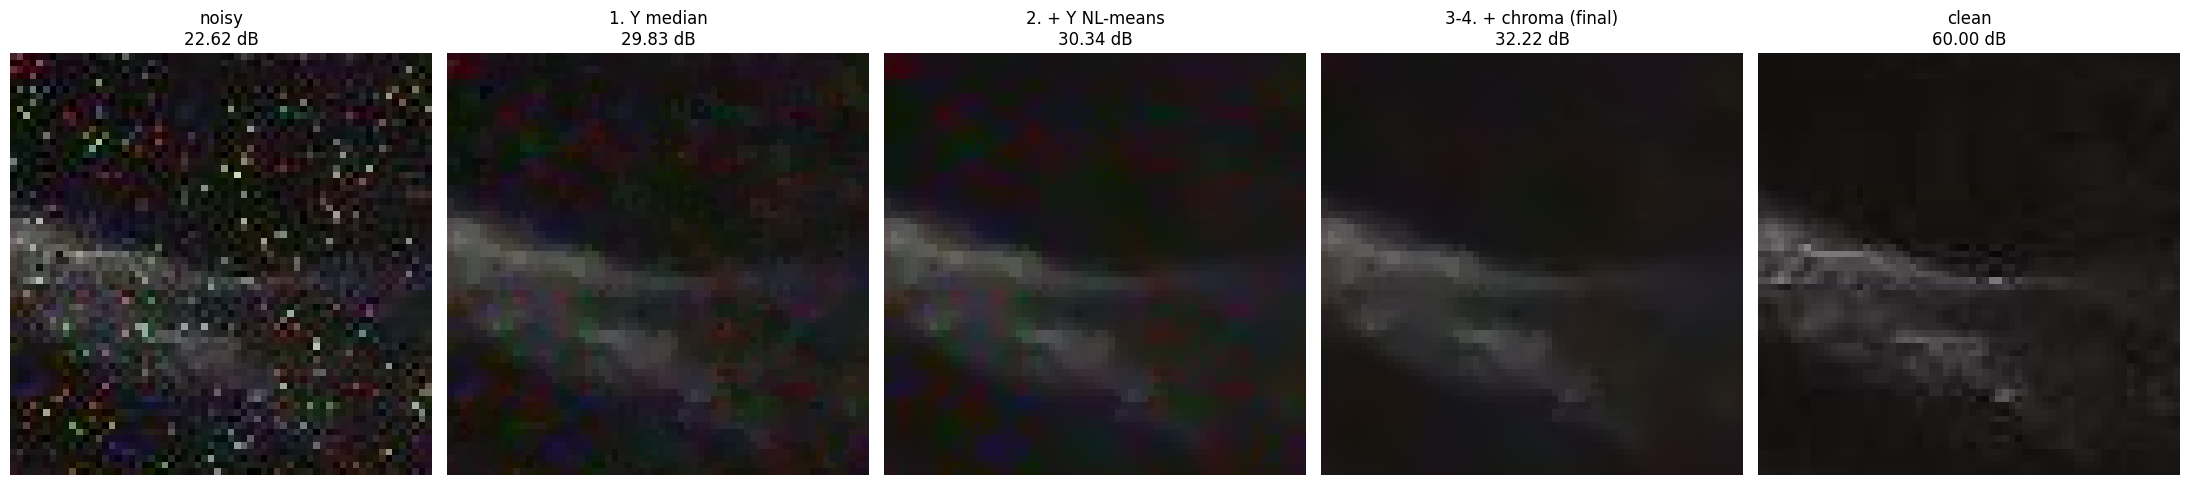

In [6]:
def merge_bgr(y, cr, cb):
    return cv2.cvtColor(cv2.merge([y, cr, cb]), cv2.COLOR_YCrCb2BGR)


y, cr, cb = cv2.split(cv2.cvtColor(n, cv2.COLOR_BGR2YCrCb))
y_med = cv2.medianBlur(y, LUMA_MEDIAN)
y_nlm = cv2.fastNlMeansDenoising(y_med, None, LUMA_NLM_H, NLM_TEMPLATE, NLM_SEARCH)

stages = {
    "noisy": n,
    "1. Y median": merge_bgr(y_med, cr, cb),
    "2. + Y NL-means": merge_bgr(y_nlm, cr, cb),
    "3-4. + chroma (final)": merge_bgr(y_nlm, denoise_chroma(cr), denoise_chroma(cb)),
    "clean": c,
}
show([crop(img, CY, CX, CS) for img in stages.values()],
     [f"{k}\n{psnr(v, c):.2f} dB" for k, v in stages.items()], figsize=(22, 5))

The final result is still smoother than the clean image: the 3×3 median also erases some genuine fine texture.
That loss can't be recovered afterwards, and it is the main limit of this approach (§6).

### 2.2 Why a median first (and only 3×3)

A median picks the middle value of the 3×3 neighbourhood, so a single outlier, however bright, never reaches the output.
A mean or Gaussian would instead **average** the impulse into its neighbours and leave a grey smudge.
A bigger median (5×5) removes more noise but erases thin painting strokes too, which is why it scores lower than 3×3.

The median is applied **only to Y** here. Impulses are mostly a brightness phenomenon after JPEG, and the colour is handled
separately and more strongly in the chroma branch.

### 2.3 How NL-means removes the JPEG halo without blurring the painting

After the median, Y still has a low-amplitude grainy halo. NL-means (Non-Local means) replaces every pixel by a **weighted
average of the pixels in an 11×11 search window**. The weight of a candidate pixel *q* depends on how similar the **7×7 patch
around q** is to the 7×7 patch around the pixel being denoised *p*:

$$ w(p,q) = \exp\left(-\frac{\overline{(P_p - P_q)^2}}{h^2}\right) $$

- Pixels whose surroundings look the same (same side of an edge, same texture) get high weight and are averaged, **removing noise**.
- Pixels across an edge, or on a different texture, have very different patches, get ~0 weight and **are not mixed in**.
  So edges and brush strokes survive.
- `h` sets how different two patches can be and still be averaged. Too big blurs detail, too small leaves noise (see §3.3).

A plain median also works on Y but leaves the halo; a bilateral filter compares **single pixel values** instead of patches,
so it can't tell grainy noise from fine texture as well.

The weight maps below are computed by hand, with the same formula OpenCV uses, for three kinds of pixel:
a **unique detail** (the strongest local peak), a pixel on an **edge**, and one in a **flat** area.

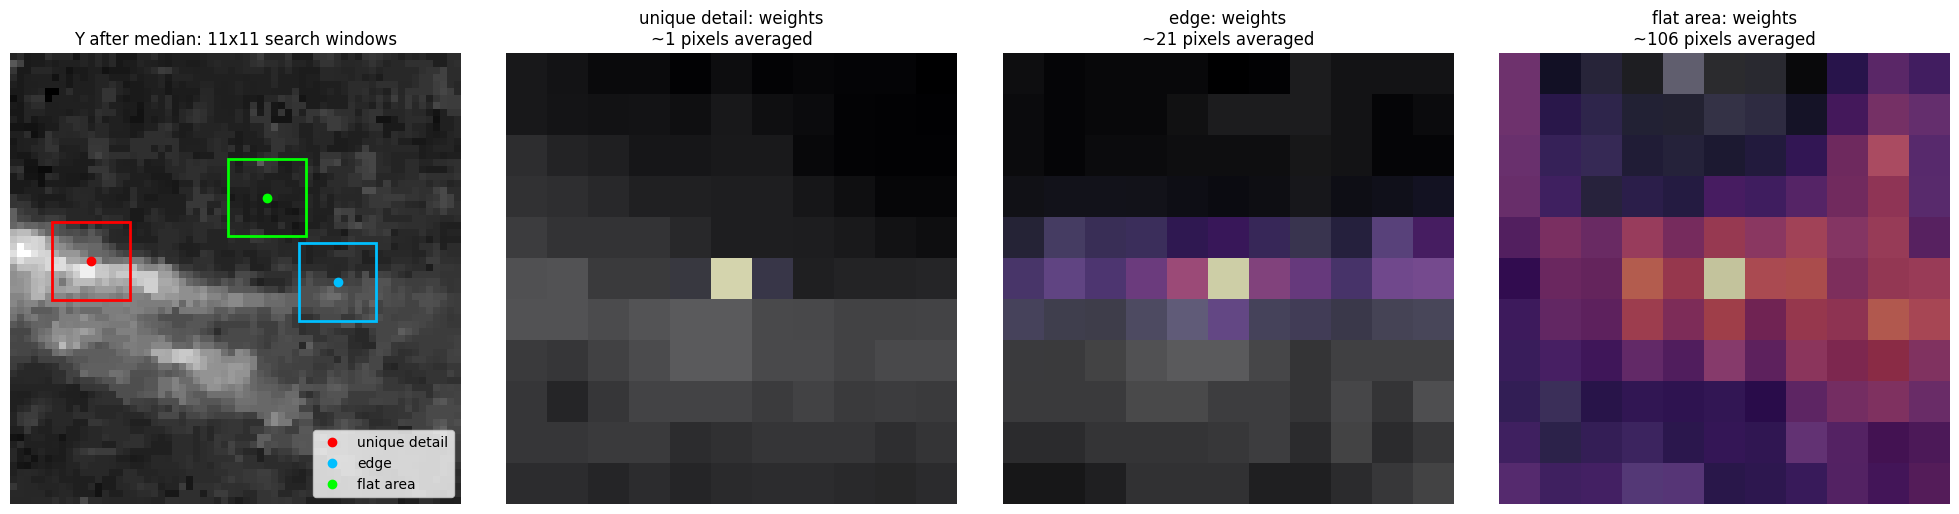

In [7]:
def nlm_weight_map(y, py, px, h=LUMA_NLM_H, t=NLM_TEMPLATE, s=NLM_SEARCH):
    """NL-means weights of every pixel in the search window around (py, px) (same formula as OpenCV)."""
    r, R = t // 2, s // 2
    yf = y.astype(np.float64)
    ref = yf[py - r:py + r + 1, px - r:px + r + 1]
    w = np.zeros((s, s))
    for dy in range(-R, R + 1):
        for dx in range(-R, R + 1):
            q = yf[py + dy - r:py + dy + r + 1, px + dx - r:px + dx + r + 1]
            w[dy + R, dx + R] = np.exp(-np.mean((ref - q) ** 2) / h ** 2)
    return w / w.sum()


def effective_neighbours(w):
    """How many pixels effectively take part in the average (1 = the pixel keeps its own value)."""
    return 1 / np.sum(w ** 2)


y_crop = crop(y_med, CY, CX, CS)
grad = cv2.magnitude(cv2.Sobel(y_crop, cv2.CV_64F, 1, 0), cv2.Sobel(y_crop, cv2.CV_64F, 0, 1))
m = NLM_SEARCH // 2 + NLM_TEMPLATE // 2
inner = grad[m:-m, m:-m]

# unique detail: strongest gradient peak; flat: weakest local gradient
detail_p = np.add(np.unravel_index(np.argmax(inner), inner.shape), m)
flat_p = np.add(np.unravel_index(np.argmin(cv2.blur(inner, (5, 5))), inner.shape), m)
# edge: among the 10% strongest-gradient pixels, the one lying on the longest coherent edge
# (the one whose patch is repeated most often in its search window)
candidates = np.argwhere(inner >= np.percentile(inner, 90)) + m
edge_p = max(candidates, key=lambda p: effective_neighbours(nlm_weight_map(y_med, CY + p[0], CX + p[1])))

cases = [(detail_p, "red", "unique detail"), (edge_p, "deepskyblue", "edge"), (flat_p, "lime", "flat area")]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(y_crop, cmap="gray", interpolation="nearest")
R = NLM_SEARCH // 2
for (py, px), color, label in cases:
    axes[0].add_patch(Rectangle((px - R - 0.5, py - R - 0.5), NLM_SEARCH, NLM_SEARCH, fill=False, color=color, lw=2))
    axes[0].plot(px, py, "o", color=color, label=label)
axes[0].legend(loc="lower right")
axes[0].set_title("Y after median: 11x11 search windows")
for ax, ((py, px), color, label) in zip(axes[1:], cases):
    w = nlm_weight_map(y_med, CY + py, CX + px)
    ax.imshow(crop(y_crop, py - R, px - R, NLM_SEARCH), cmap="gray", interpolation="nearest")
    ax.imshow(w, cmap="magma", alpha=0.65, interpolation="nearest")
    ax.set_title(f"{label}: weights\n~{effective_neighbours(w):.0f} pixels averaged")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

(The weight maps are drawn over the search window; bright = high weight.)

- **Unique detail**: no other patch in the window looks like it, so the pixel essentially **keeps its own value**.
  NL-means does not erase isolated real details (the median has already removed the impulses, which would otherwise be "unique" too).
- **Edge**: the weight follows the **edge direction**. Pixels across the edge get ~0, so the edge stays sharp.
- **Flat area**: the weight spreads over the whole window, giving maximum noise reduction where it's safe.

### 2.4 Why the colour can be smoothed so hard

The clean images are JPEGs too, so their colour channels were **already stored at half resolution and are smooth**. Practically
all the detail of a painting lives in Y. We can check this by applying the chroma filter to the **clean** images and
measuring how much they change, and doing the same to Y for comparison:

In [8]:
rows = []
for i in impulse_ids:
    yc, crc, cbc = cv2.split(cv2.cvtColor(clean[i], cv2.COLOR_BGR2YCrCb))
    rows.append({
        "id": i,
        "chroma filter on clean Cr/Cb (PSNR dB)": np.mean([psnr(denoise_chroma(ch), ch) for ch in (crc, cbc)]),
        "same filter on clean Y (PSNR dB)": psnr(denoise_chroma(yc), yc),
    })
display(pd.DataFrame(rows).set_index("id").round(1))

,chroma filter on clean Cr/Cb (PSNR dB),same filter on clean Y (PSNR dB)
id,,
3,46.2,25.5
8,56.5,25.9
12,47.6,28.4
17,54.8,27.8
19,50.4,16.1
22,44.3,23.3
23,46.7,25.9
24,44.5,25.7
25,45.0,26.6


A high PSNR means "barely changed". The strong median + Gaussian hardly alters clean colour channels, but would wreck the
brightness channel. So in Cr/Cb we can afford a big filter that flattens the JPEG colour blotches, which a 3×3 median can't reach.

## 3. Why this is the best option

### 3.1 Comparison with all the methods tried

Mean over the 9 impulse-noise images (detector perfect, so the other 21 images are untouched by every method).
*Wins* = number of images where the method beats the Week 3 filter (median 3×3).

In [9]:
summary = pd.read_csv(SEARCH_DIR / "denoising_search_summary.csv")
per_image = pd.read_csv(SEARCH_DIR / "denoising_search.csv")
CHOSEN = "Y nlm h4 | C med5+g21"
display(summary.set_index("method").round(3))

,family,psnr,ssim,psnr_wins,ssim_wins,s_per_mp
method,,,,,,
Y nlm h4 | C med5+g21,luma/chroma,31.615,0.874,9,9,0.185
Y nlm h4 | C med7+g15,luma/chroma,31.607,0.874,9,9,0.254
Y nlm h4 | C med5+g15,luma/chroma,31.556,0.874,9,9,0.184
Y nlm h4 | C med5+g31,luma/chroma,31.543,0.874,9,9,0.190
Y nlm h3 | C med5+g15,luma/chroma,31.526,0.877,9,9,0.185
Y nlm h5 | C med5+g15,luma/chroma,31.499,0.866,9,7,0.177
Y nlm h5 | C med7+g9,luma/chroma,31.447,0.866,9,7,0.260
Y nlm h4 | C med5+g9,luma/chroma,31.368,0.874,9,9,0.187
median3 + nl-means h5/10,two-stage,31.337,0.862,9,8,0.620


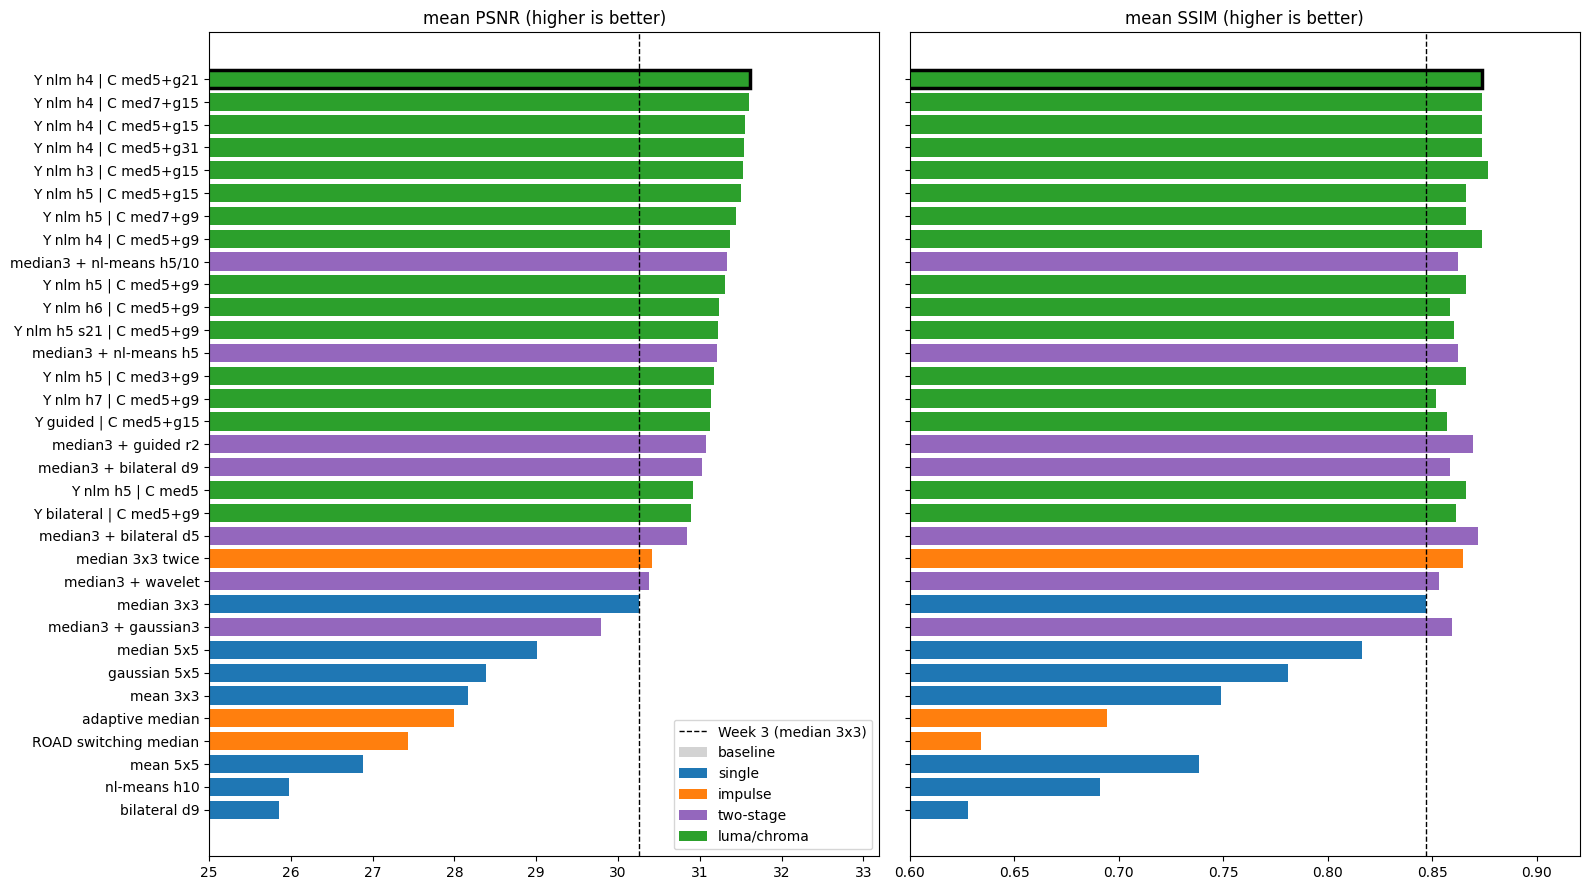

In [10]:
family_colors = {"baseline": "lightgray", "single": "tab:blue", "impulse": "tab:orange",
                 "two-stage": "tab:purple", "luma/chroma": "tab:green"}
s = summary[summary["method"] != "none"].sort_values("psnr")
week3 = summary.set_index("method").loc["median 3x3"]

fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharey=True)
for ax, metric, xlim in [(axes[0], "psnr", (25, None)), (axes[1], "ssim", (0.6, None))]:
    colors = [family_colors[f] for f in s["family"]]
    bars = ax.barh(s["method"], s[metric], color=colors)
    for bar, name in zip(bars, s["method"]):
        if name == CHOSEN:
            bar.set_edgecolor("black"); bar.set_linewidth(2.5)
    ax.axvline(week3[metric], color="black", ls="--", lw=1, label="Week 3 (median 3x3)")
    ax.set_xlim(*xlim)
    ax.set_title(f"mean {metric.upper()} (higher is better)")
for fam, col in family_colors.items():
    axes[0].barh([s["method"].iloc[0]], [0], color=col, label=fam)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

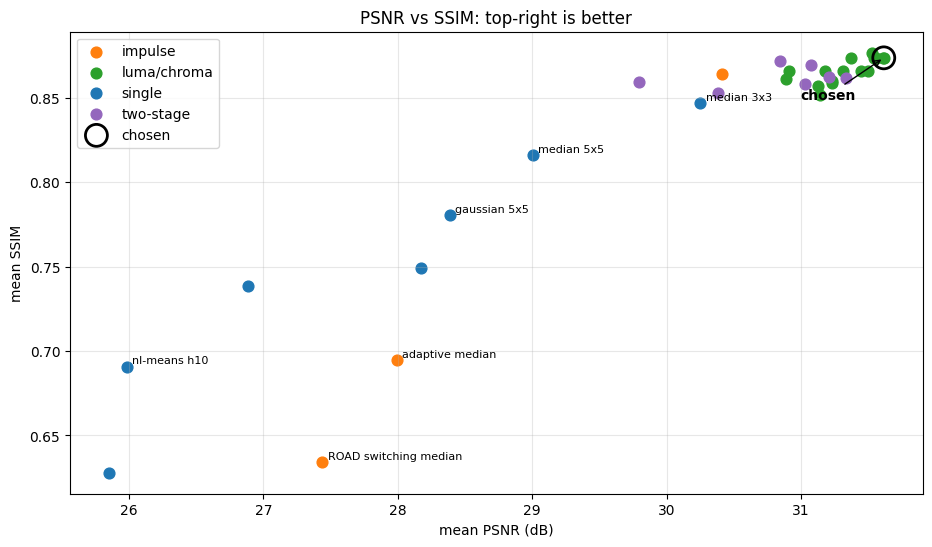

In [11]:
LABELLED = {"median 3x3", "median 5x5", "gaussian 5x5", "nl-means h10", "adaptive median", "ROAD switching median"}
fig, ax = plt.subplots(figsize=(11, 6))
for fam, g in summary[summary["method"] != "none"].groupby("family"):
    ax.scatter(g["psnr"], g["ssim"], color=family_colors[fam], label=fam, s=60)
    for _, r in g.iterrows():
        if r["method"] in LABELLED:
            ax.annotate(r["method"], (r["psnr"], r["ssim"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
chosen = summary.set_index("method").loc[CHOSEN]
ax.scatter(chosen["psnr"], chosen["ssim"], s=250, facecolors="none", edgecolors="black", lw=2, label="chosen")
ax.annotate("chosen", (chosen["psnr"], chosen["ssim"]), xytext=(-60, -30), textcoords="offset points",
            arrowprops={"arrowstyle": "->"}, fontsize=10, fontweight="bold")
ax.set_xlabel("mean PSNR (dB)")
ax.set_ylabel("mean SSIM")
ax.set_title("PSNR vs SSIM: top-right is better")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

All the two-stage methods (purple and green) sit in the top-right corner, above the Week 3 median. Within that cluster,
the luma/chroma variants (green) reach the highest PSNR without giving up SSIM.

### 3.2 Contribution of each component (ablation)

Starting from Week 3 and adding one idea at a time. PSNR is also split into **Y** and **Cr/Cb** to show which branch improves what.

In [12]:
def ycc_psnr(img, ref):
    a = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
    b = cv2.cvtColor(ref, cv2.COLOR_BGR2YCrCb)
    return psnr(a[..., 0], b[..., 0]), psnr(a[..., 1:], b[..., 1:])


def luma_chroma(img, luma_fn, chroma_fn):
    y, cr, cb = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb))
    return merge_bgr(luma_fn(y), chroma_fn(cr), chroma_fn(cb))


med3 = lambda ch: cv2.medianBlur(ch, 3)
ablation = {
    "noisy (no filter)": lambda x: x,
    "Week 3: median 3x3 on BGR": lambda x: cv2.medianBlur(x, 3),
    "median 3x3 on Y, Cr, Cb": lambda x: luma_chroma(x, med3, med3),
    "+ NL-means on Y": lambda x: luma_chroma(x, denoise_luma, med3),
    "+ strong chroma filter (final)": lambda x: luma_chroma(x, denoise_luma, denoise_chroma),
    "strong chroma only (no NL-means)": lambda x: luma_chroma(x, med3, denoise_chroma),
}

rows = []
outputs = {}
for name, fn in ablation.items():
    for i in impulse_ids:
        out = fn(noisy[i])
        py, pc = ycc_psnr(out, clean[i])
        rows.append({"step": name, "id": i, "PSNR": psnr(out, clean[i]), "SSIM": ssim(out, clean[i]),
                     "PSNR Y": py, "PSNR CrCb": pc})
ablation_df = pd.DataFrame(rows)
display(ablation_df.groupby("step", sort=False)[["PSNR", "SSIM", "PSNR Y", "PSNR CrCb"]].mean().round(3))

,PSNR,SSIM,PSNR Y,PSNR CrCb
step,,,,
noisy (no filter),23.351,0.468,23.585,37.612
Week 3: median 3x3 on BGR,30.251,0.847,31.844,38.253
"median 3x3 on Y, Cr, Cb",30.210,0.842,31.752,38.516
+ NL-means on Y,30.562,0.874,32.304,38.519
+ strong chroma filter (final),31.615,0.874,32.304,43.130
strong chroma only (no NL-means),31.143,0.842,31.751,43.133


- Moving the median from BGR to YCrCb changes almost nothing; the gain is not in the colour space itself.
- **NL-means on Y** is what raises **SSIM** (structure) and PSNR-Y: it removes the JPEG halo left by the median.
- The **strong chroma filter** is what raises **PSNR-CrCb**: it removes the colour blotches. It doesn't affect SSIM,
  which is measured on brightness only.
- The two improvements are **independent and add up**, which is why the combination wins.

### 3.3 Is the choice robust or just tuned to these 9 images?

If the best result only showed up at one exact parameter value it would be suspicious. The plots below vary one parameter
at a time (values from the search). Performance changes smoothly and there's a broad plateau, so the choice is not a lucky spike.

- **Luma h** trades PSNR against SSIM: lower h keeps more structure (SSIM ↑) but leaves more grain. h = 3–4 is the sweet spot;
  h = 4 keeps the best PSNR with almost the best SSIM. (SSIM only sees brightness, so the two chroma settings overlap there.)
- **Chroma kernel**: anything from 15 to 31 is within 0.07 dB. 21 is the centre of the plateau.

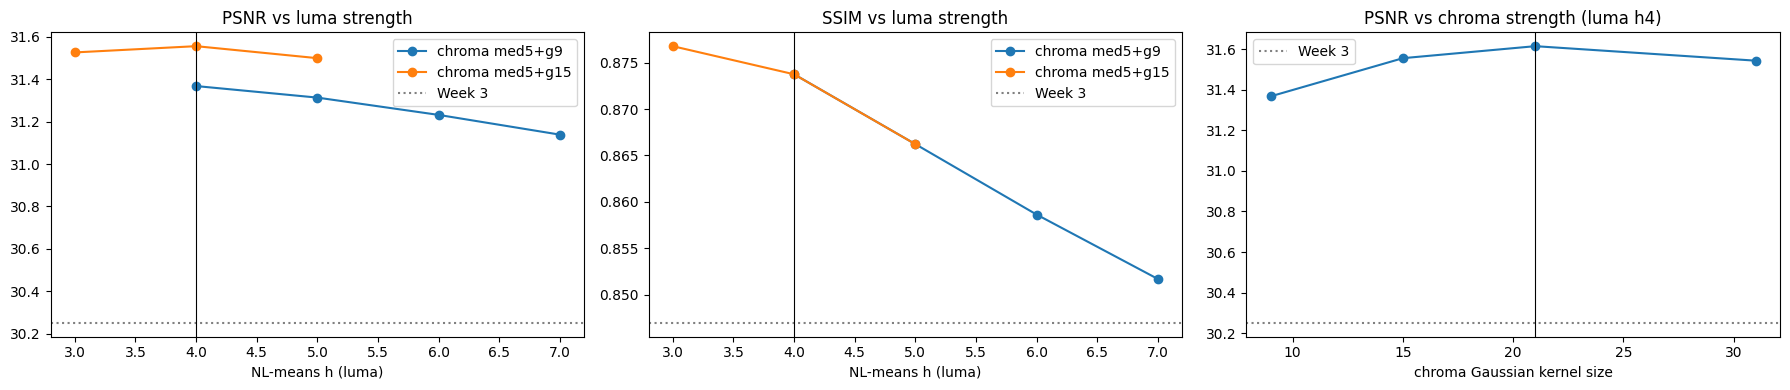

Chosen method beats Week 3 on 9/9 images in PSNR and 9/9 in SSIM


id,3,8,12,17,19,22,23,24,25
PSNR gain vs Week 3 (dB),1.19,2.0,1.4,2.25,0.38,0.8,1.61,1.22,1.42


In [13]:
idx = summary.set_index("method")

h_sweeps = {"chroma med5+g9": [(h, f"Y nlm h{h} | C med5+g9") for h in (4, 5, 6, 7)],
            "chroma med5+g15": [(h, f"Y nlm h{h} | C med5+g15") for h in (3, 4, 5)]}
g_sweep = [(g, f"Y nlm h4 | C med5+g{g}") for g in (9, 15, 21, 31)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for label, sweep in h_sweeps.items():
    hs = [h for h, _ in sweep]
    axes[0].plot(hs, [idx.loc[m, "psnr"] for _, m in sweep], "o-", label=label)
    axes[1].plot(hs, [idx.loc[m, "ssim"] for _, m in sweep], "o-", label=label)
for ax, metric in zip(axes[:2], ["psnr", "ssim"]):
    ax.axhline(week3[metric], color="gray", ls=":", label="Week 3")
    ax.axvline(LUMA_NLM_H, color="black", lw=0.8)
    ax.set_xlabel("NL-means h (luma)")
    ax.set_title(f"{metric.upper()} vs luma strength")
    ax.legend()

gs = [g for g, _ in g_sweep]
axes[2].plot(gs, [idx.loc[m, "psnr"] for _, m in g_sweep], "o-")
axes[2].axhline(week3["psnr"], color="gray", ls=":", label="Week 3")
axes[2].axvline(CHROMA_GAUSS, color="black", lw=0.8)
axes[2].set_xlabel("chroma Gaussian kernel size")
axes[2].set_title("PSNR vs chroma strength (luma h4)")
axes[2].legend()
plt.tight_layout()
plt.show()

wins = per_image.pivot(index="id", columns="method", values=["psnr", "ssim"])
better_psnr = (wins["psnr"][CHOSEN] > wins["psnr"]["median 3x3"]).sum()
better_ssim = (wins["ssim"][CHOSEN] > wins["ssim"]["median 3x3"]).sum()
print(f"Chosen method beats Week 3 on {better_psnr}/{len(wins)} images in PSNR and {better_ssim}/{len(wins)} in SSIM")
display((wins["psnr"][CHOSEN] - wins["psnr"]["median 3x3"]).rename("PSNR gain vs Week 3 (dB)").round(2).to_frame().T)

### 3.4 Why the other families lose

- **Linear filters (mean, Gaussian)** average the impulse into its neighbours, so the noise is spread rather than removed, and edges are blurred.
- **NL-means or bilateral alone** don't remove the impulses at all. An impulse makes its patch unlike any other patch (NL-means),
  or unlike its neighbours' values (bilateral), so it gets averaged only with itself and survives. They need the median in front.
- **Switching / adaptive / ROAD medians** are the textbook answer for impulse noise because they replace *only* the detected
  impulse pixels and keep everything else intact. Here they are **worse than a plain median**: the JPEG halo around each impulse
  is not detected as an impulse, so it is left untouched.
- **A bigger median (5×5)** removes more halo but also erases thin brush strokes, so it scores below 3×3.
  **Repeating the 3×3 median** helps a little (+0.16 dB), but a median is not designed for low-amplitude grain.
- **Median + bilateral / guided / wavelet** are the right idea (two stages) and all beat Week 3, but per-pixel smoothers
  separate noise from texture less well than patch comparison, and they ignore the colour blotches.
- **Median + colour NL-means** comes close, but filters colour as weakly as brightness and is ~3× slower.

### 3.5 Runtime

In [14]:
rt = summary.set_index("method").loc[["median 3x3", "median3 + bilateral d5", "median3 + nl-means h5/10",
                                      "nl-means h10", CHOSEN], ["psnr", "ssim", "s_per_mp"]]
display(rt.rename(columns={"s_per_mp": "seconds per megapixel"}).round(3))

,psnr,ssim,seconds per megapixel
method,,,
median 3x3,30.251,0.847,0.002
median3 + bilateral d5,30.846,0.872,0.007
median3 + nl-means h5/10,31.337,0.862,0.620
nl-means h10,25.982,0.691,2.312
Y nlm h4 | C med5+g21,31.615,0.874,0.185


NL-means on **one** channel with a small search window (11×11) costs about **0.2 s per megapixel**: ~1–2 s for the largest
query images. That's ~12× cheaper than the colour NL-means tried in Week 3 (h=10, 21×21 window), and it only runs on the
images the detector flags.

## 4. Whole-pipeline check on all 30 QSD1-W4 images

The detector decides whether to filter at all. It must not touch the hue-changed or clean images.

In [15]:
rows = []
for i in ids:
    frac = impulse_fraction(noisy[i])
    for name, fn in [("Week 3", week3_denoise), ("Week 4", denoise_image)]:
        out = fn(noisy[i])
        rows.append({"id": i, "augmentation": augmentations[i], "method": name, "impulse fraction": frac,
                     "filtered": not np.array_equal(out, noisy[i]),
                     "PSNR": psnr(out, clean[i]), "SSIM": ssim(out, clean[i])})
full = pd.DataFrame(rows)

display(full.pivot_table(index="augmentation", columns="method", values=["PSNR", "SSIM", "filtered"],
                         aggfunc="mean").round(3))

frac = full[full["method"] == "Week 4"].set_index("id")["impulse fraction"]
is_imp = pd.Series({i: i in impulse_ids for i in ids})
print(f"Detector margin: noisy images have >= {frac[is_imp].min():.2%} isolated pixels, "
      f"other images <= {frac[~is_imp].max():.2%} (threshold {DETECT_FRACTION:.0%})")

PSNR           SSIM        filtered       
method               Week 3  Week 4 Week 3 Week 4   Week 3 Week 4
augmentation                                                     
None                 60.000  60.000  1.000  1.000      0.0    0.0
None-MultiplyHue     38.279  38.279  0.986  0.986      0.0    0.0
UnnamedImpulseNoise  30.251  31.615  0.847  0.874      1.0    1.0

Detector margin: noisy images have >= 1.74% isolated pixels, other images <= 0.25% (threshold 1%)


## 5. Visual comparison: Week 3 vs Week 4

Error maps show |result − clean| (brighter = more error, same scale for both).

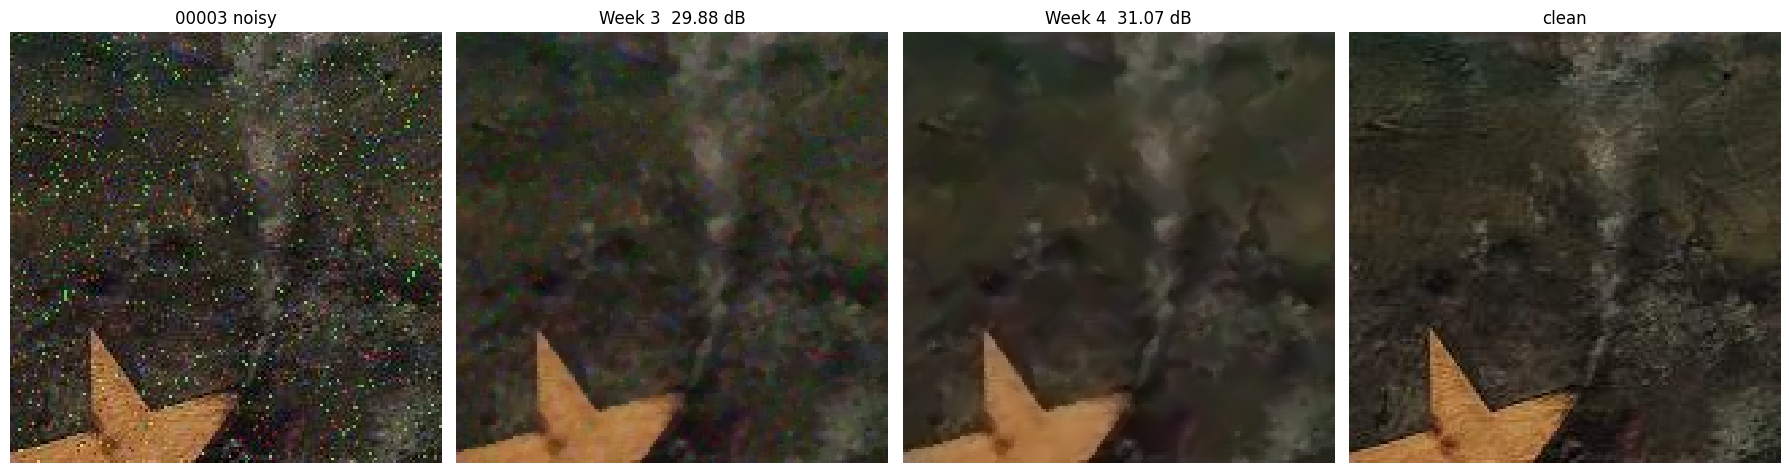

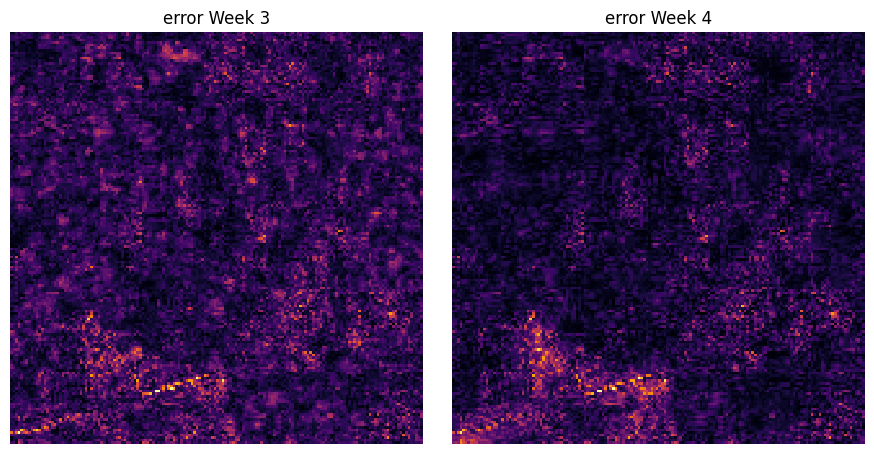

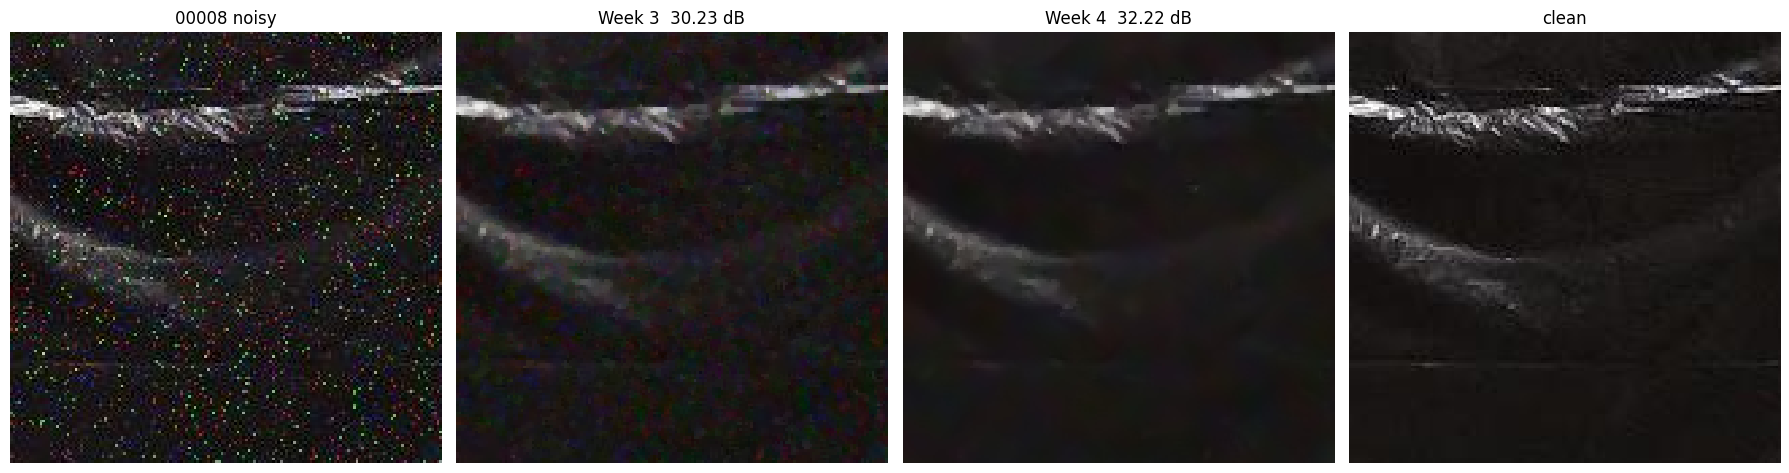

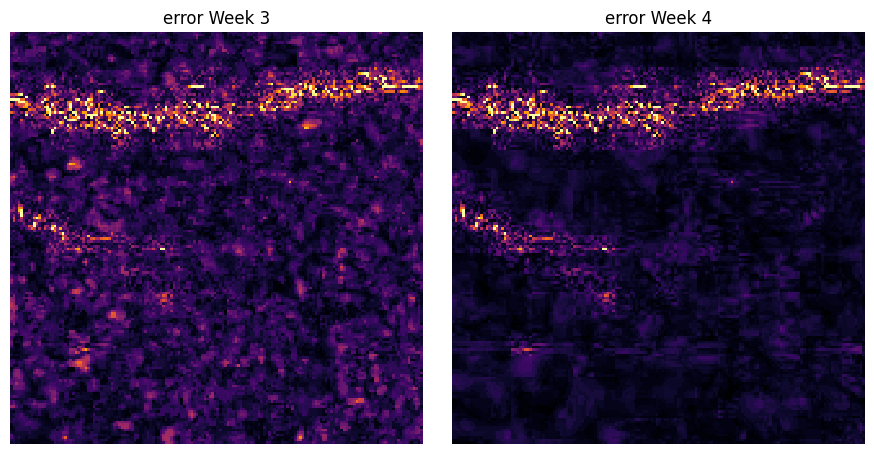

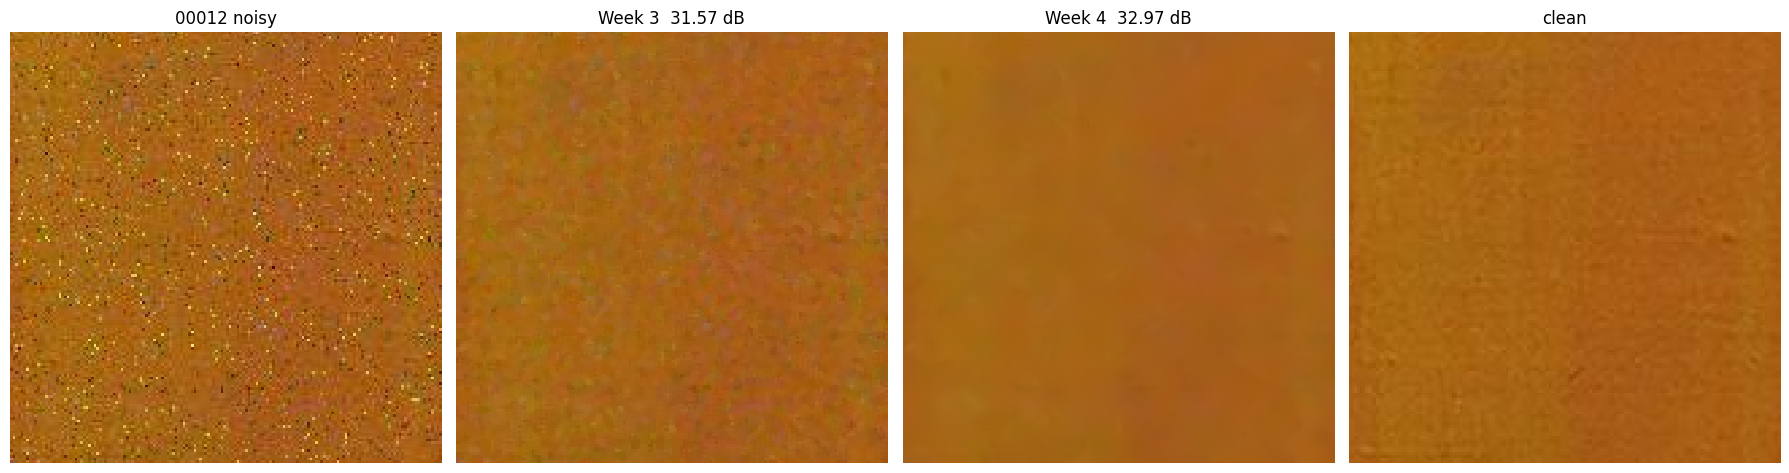

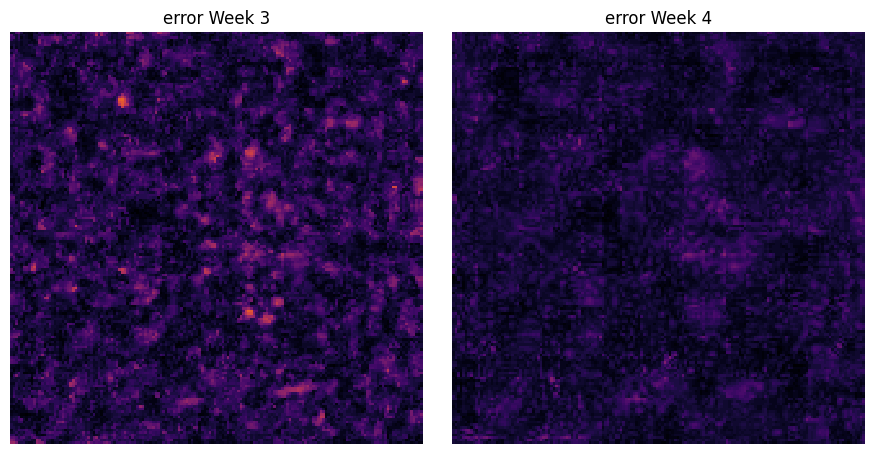

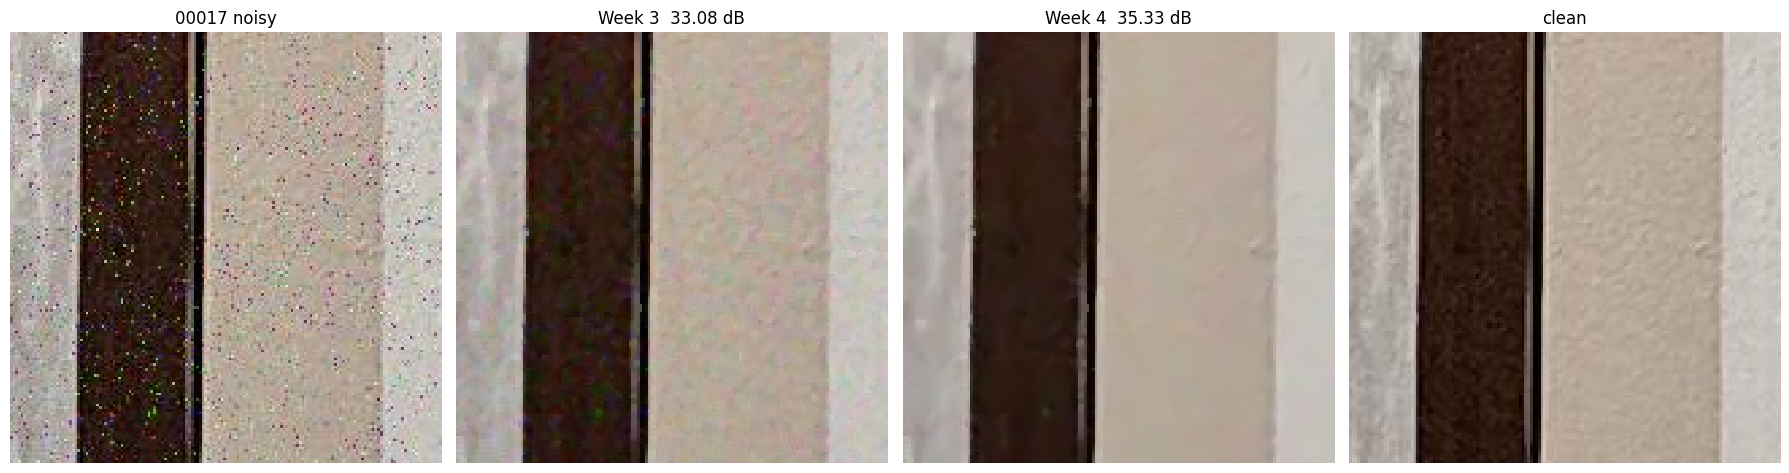

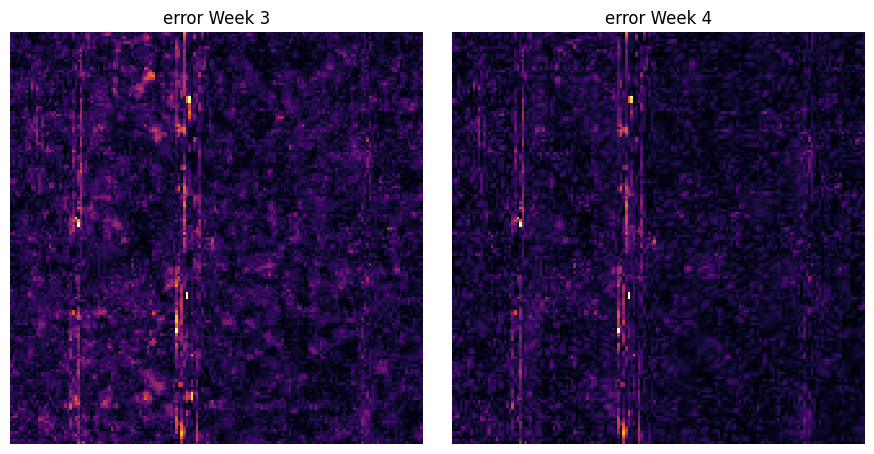

In [16]:
def error_map(img, ref):
    return np.abs(img.astype(np.int16) - ref.astype(np.int16)).max(axis=2)


for i in impulse_ids[:4]:
    h, w = noisy[i].shape[:2]
    size = min(160, h, w)
    y0, x0 = (h - size) // 2, (w - size) // 2
    w3, w4 = week3_denoise(noisy[i]), denoise_image(noisy[i])
    show([crop(im, y0, x0, size) for im in (noisy[i], w3, w4, clean[i])],
         [f"{i:05d} noisy", f"Week 3  {psnr(w3, clean[i]):.2f} dB", f"Week 4  {psnr(w4, clean[i]):.2f} dB", "clean"],
         figsize=(18, 4.8))
    show([crop(error_map(im, clean[i]), y0, x0, size) for im in (w3, w4)],
         ["error Week 3", "error Week 4"], cmap="inferno", vmin=0, vmax=60, figsize=(9, 4.5))

## 6. Limitations and next steps

- **Small evaluation set**: 9 noisy images. The parameters sit on a broad plateau (§3.3) and the method wins on every image,
  but the gains on the test set may be a bit smaller.
- **Detail lost by the median** is not recovered. Even on a clean image, a 3×3 median changes fine texture, which puts a
  ceiling on any "median first" method. Going past it would need a filter that is not median-based at all (e.g. BM3D-style
  collaborative filtering, which is out of scope for classical Week 4 tools).
- **PSNR/SSIM ≠ retrieval**: the final check is the retrieval mAP of the Week 4 pipeline with this denoiser.
- To use it in the pipeline, copy `denoise_luma`, `denoise_chroma` and `denoise_image` (plus the constants) into `w4/utils.py`.